In [1]:
import torch

print("CUDA Available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


CUDA Available: True
GPU: NVIDIA GeForce GTX 1650 Ti


In [2]:
import os
import numpy as np
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import torchvision.transforms as transforms
import torchvision.models as models

from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
class MRIDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            img = Image.open(self.paths[idx]).convert("RGB")
        except:
            return self.__getitem__((idx + 1) % len(self.paths))

        if self.transform:
            img = self.transform(img)

        return img, self.labels[idx]


In [4]:
# change this path
root = "C:/Users/sanja/Desktop/MRI_Project/AD_DATASET/Processed_Final"

classes = ["Non_Demented", "Very_mild_Dementia", "Mild_Dementia", "Moderate_Dementia"]

image_paths = []
labels = []

for idx, cls in enumerate(classes):
    folder = os.path.join(root, cls)
    for f in os.listdir(folder):
        image_paths.append(os.path.join(folder, f))
        labels.append(idx)

labels = np.array(labels)


In [5]:
train_paths, test_paths, train_labels, test_labels = train_test_split(
    image_paths, labels, test_size=0.2, stratify=labels, random_state=42
)


In [6]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
])


In [7]:
class_counts = np.bincount(train_labels)
class_weights = 1.0 / class_counts
sample_weights = class_weights[train_labels]

sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)


In [8]:
train_ds = MRIDataset(train_paths, train_labels, transform=train_transform)
test_ds  = MRIDataset(test_paths,  test_labels,  transform=test_transform)

train_loader = DataLoader(train_ds, batch_size=32, sampler=sampler,
                          num_workers=0, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False,
                         num_workers=0, pin_memory=True)


In [9]:
vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

# Freeze base model
for param in vgg.features.parameters():
    param.requires_grad = False

# Custom classifier
vgg.classifier = nn.Sequential(
    nn.Linear(25088, 4096),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(4096, 1024),
    nn.ReLU(),
    nn.Dropout(0.4),

    nn.Linear(1024, 4)   # 4 classes
)

model = vgg.to(device)


In [10]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=1e-4, weight_decay=1e-4)

scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)


In [11]:
num_epochs = 10

train_loss_hist = []
val_loss_hist = []
train_acc_hist = []
val_acc_hist = []

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    
    model.train()
    running_loss = 0
    correct = 0
    total = 0
    
    pbar = tqdm(train_loader, desc="Training", ncols=120, colour="green")
    
    for imgs, lbls in pbar:
        imgs, lbls = imgs.to(device), lbls.to(device)

        outputs = model(imgs)
        loss = criterion(outputs, lbls)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, preds = outputs.max(1)
        total += lbls.size(0)
        correct += preds.eq(lbls).sum().item()

        pbar.set_postfix(loss=loss.item(), acc=correct/total)

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total

    # Validation loop
    model.eval()
    val_loss, val_correct, val_total = 0, 0, 0

    with torch.no_grad():
        for imgs, lbls in test_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)

            out = model(imgs)
            loss = criterion(out, lbls)

            val_loss += loss.item()
            _, preds = out.max(1)
            val_correct += preds.eq(lbls).sum().item()
            val_total += lbls.size(0)

    val_loss /= len(test_loader)
    val_acc = val_correct / val_total

    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)
    train_acc_hist.append(train_acc)
    val_acc_hist.append(val_acc)

    scheduler.step()

    print(f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")



Epoch 1/10


Training: 100%|███████████████████████████████████████████████| 1950/1950 [29:09<00:00,  1.11it/s, acc=0.757, loss=0.31]


Train Acc: 0.7568 | Val Acc: 0.8138

Epoch 2/10


Training: 100%|████████████████████████████████████████████████| 1950/1950 [31:18<00:00,  1.04it/s, acc=0.857, loss=0.2]


Train Acc: 0.8572 | Val Acc: 0.8747

Epoch 3/10


...

Train Acc: 0.9577 | Val Acc: 0.9523

Epoch 9/10


Training: 100%|█████████████████████████████████████████████| 1950/1950 [29:00<00:00,  1.12it/s, acc=0.961, loss=0.0489]


Train Acc: 0.9612 | Val Acc: 0.9743

Epoch 10/10


Training: 100%|██████████████████████████████████████████████| 1950/1950 [28:57<00:00,  1.12it/s, acc=0.964, loss=0.322]


Train Acc: 0.9640 | Val Acc: 0.9752


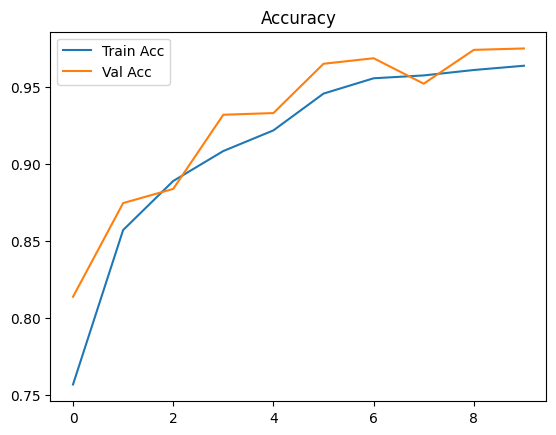

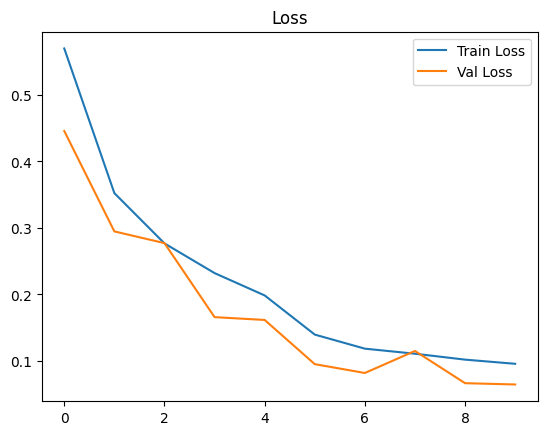

In [12]:
plt.plot(train_acc_hist, label="Train Acc")
plt.plot(val_acc_hist, label="Val Acc")
plt.legend()
plt.title("Accuracy")
plt.show()

plt.plot(train_loss_hist, label="Train Loss")
plt.plot(val_loss_hist, label="Val Loss")
plt.legend()
plt.title("Loss")
plt.show()


In [13]:
model.eval()

all_probs = []
all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        out = model(imgs)

        probs = torch.softmax(out, dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)

        all_probs.extend(probs)
        all_preds.extend(preds)
        all_labels.extend(lbls.numpy())


In [14]:
print(classification_report(all_labels, all_preds, target_names=classes))


                    precision    recall  f1-score   support

      Non_Demented       0.99      0.98      0.98      8000
Very_mild_Dementia       0.95      0.96      0.95      4000
     Mild_Dementia       0.95      0.98      0.97      2000
 Moderate_Dementia       0.99      1.00      1.00      1600

          accuracy                           0.98     15600
         macro avg       0.97      0.98      0.97     15600
      weighted avg       0.98      0.98      0.98     15600



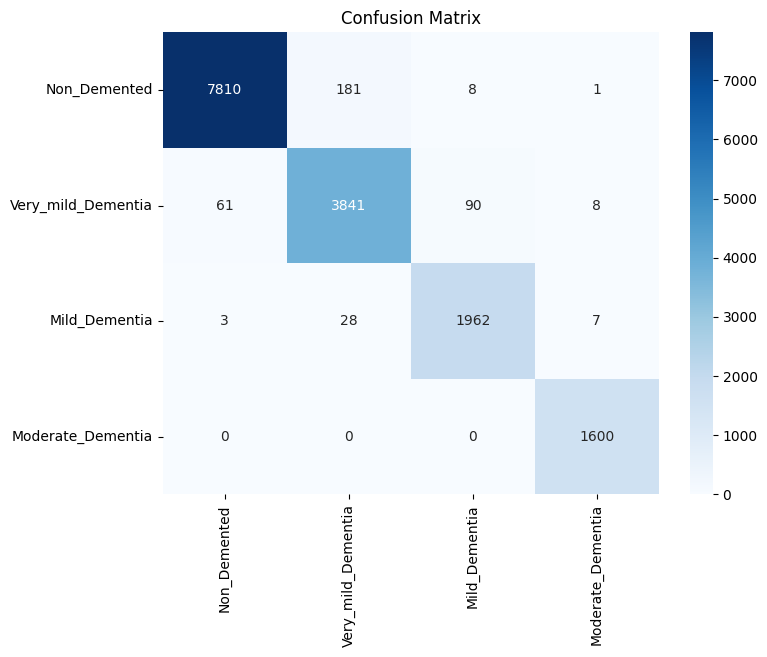

In [15]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix")
plt.show()


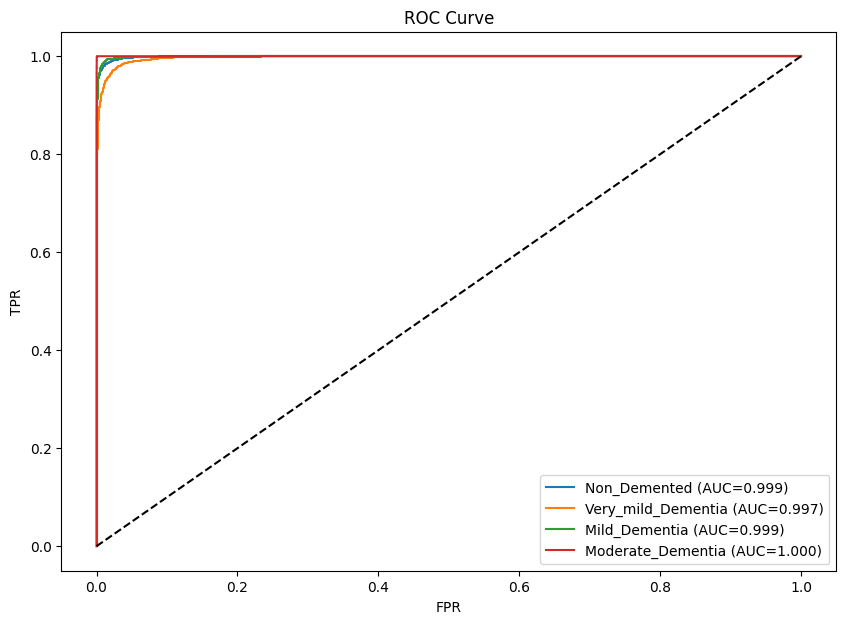

In [16]:
y_bin = label_binarize(all_labels, classes=[0,1,2,3])
all_probs = np.array(all_probs)

plt.figure(figsize=(10,7))

for i in range(4):
    fpr, tpr, _ = roc_curve(y_bin[:,i], all_probs[:,i])
    score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{classes[i]} (AUC={score:.3f})")

plt.plot([0,1],[0,1],'k--')
plt.title("ROC Curve")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.show()
